# Modelo de Aprendizado de Máquina – Risco de Hipertensão Arterial (PNS 2013)

**Projeto Integrador 4 – UNIVESP** · Análise da Hipertensão Arterial Populacional e Modelo de Aprendizado de Máquina Especialista ("Narrow AI")

Este notebook cobre toda a parte de aprendizado de máquina do projeto:

1. **Limpeza** da base bruta IBGE-PNS-2013 (445 MB) em uma base enxuta;
2. **Análise exploratória** da hipertensão na amostra;
3. **Treino e avaliação** de um modelo supervisionado de classificação (regressão logística, com Gradient Boosting como comparação);
4. **Score de risco (0 a 10)** e faixas de risco;
5. **Exportação** dos coeficientes do modelo para um arquivo que a página `pagina300-aprendizado.html` usa direto no navegador.

> ⚠️ **Aviso:** o score é uma estimativa estatística de risco para apoio à triagem. **Não é diagnóstico.** Só a medição da pressão arterial (e a avaliação do profissional de saúde) confirma a hipertensão.

**Como rodar:** ajuste `CAMINHO_PNS` na primeira célula de código e execute tudo (`Run All`).
Dependências: `pip install -r requirements.txt`.

## 1. Configuração

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, recall_score, precision_score)
from sklearn.calibration import calibration_curve

# >>> AJUSTE AQUI: caminho do arquivo PNS_2013.csv na sua máquina <<<
CAMINHO_PNS = Path("../../PNS_2013/PNS_2013.csv")

# Pastas de saída (relativas a esta pasta ml/)
PASTA_DADOS = Path("dados");   PASTA_DADOS.mkdir(exist_ok=True)
PASTA_FIGURAS = Path("figuras"); PASTA_FIGURAS.mkdir(exist_ok=True)
PASTA_SITE = Path("../src/data"); PASTA_SITE.mkdir(parents=True, exist_ok=True)

SEMENTE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

def salvar(nome):
    plt.savefig(PASTA_FIGURAS / f"{nome}.png")

## 2. Leitura da base bruta

A base tem 1.000 colunas; lemos só as ~20 que importam (`usecols`). Detalhes do arquivo, conforme o dicionário do IBGE:

* separador `;`, codificação `latin-1`, **decimais com vírgula** (`59,5`);
* células vazias = "não aplicável" (a pergunta foi pulada);
* o código `999` indica **erro de medição**.

| Variável | Significado |
|---|---|
| `V0001` | Unidade da Federação (código IBGE) |
| `UPA_PNS` | Unidade primária de amostragem (conglomerado) |
| `V0025` | Morador selecionado para o questionário individual (1 = sim) |
| `C006`, `C008` | Sexo (1 = masc., 2 = fem.), idade em anos |
| `Q001` | Última vez que mediu a pressão arterial |
| `Q002` | Algum médico já diagnosticou hipertensão? (1 = sim, 2 = só na gravidez, 3 = não) |
| `Q030` | Algum médico já diagnosticou diabetes? (1 = sim, 2 = só na gravidez, 3 = não) |
| `P050` | Fuma atualmente? (1 = diariamente, 2 = menos que diariamente, 3 = não) |
| `W00101` / `W00201` / `W00301` | Peso (kg), altura (cm), cintura (cm) – 1ª medição |
| `W00407` / `W00408` | **Pressão arterial final** sistólica / diastólica (mmHg) |

In [2]:
COLUNAS = ["V0001", "UPA_PNS", "V0025", "C006", "C008", "Q001", "Q002", "Q029", "Q030", "P050",
           "W00101", "W00201", "W00301", "W00407", "W00408"]

bruta = pd.read_csv(CAMINHO_PNS, sep=";", encoding="latin-1", usecols=COLUNAS, dtype=str)
bruta = bruta.apply(lambda s: s.str.strip()).replace("", np.nan)
print(f"Registros na base bruta: {len(bruta):,}".replace(",", "."))
bruta.head()

Registros na base bruta: 222.385


,V0001,UPA_PNS,V0025,C006,C008,P050,Q001,Q002,Q029,Q030,W00101,W00201,W00301,W00407,W00408
0,11,1100002,1,1,35,3,1,3,5,3,"59,5",162,93,95,65
1,11,1100002,0,2,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11,1100002,0,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11,1100002,0,2,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11,1100002,1,1,42,3,6,NaN,6,NaN,"81,2",169,87,133,81


## 3. Limpeza e filtros

Mantemos apenas **adultos (≥ 18 anos) que responderam ao questionário individual e tiveram a pressão arterial medida de forma válida**. A tabela abaixo mostra quantas pessoas sobram a cada passo.

In [3]:
df = bruta.copy()

# --- conversão numérica (decimal com vírgula) ---
for col in ["C008", "W00101", "W00201", "W00301", "W00407", "W00408"]:
    df[col] = pd.to_numeric(df[col].str.replace(",", ".", regex=False), errors="coerce")

funil = [("Registros na base bruta", len(df))]

df = df[df["V0025"] == "1"];                              funil.append(("Morador selecionado (questionário individual)", len(df)))
df = df[df["C008"] >= 18];                                funil.append(("Idade ≥ 18 anos", len(df)))
df = df[df["W00407"].between(60, 290) & df["W00408"].between(30, 200)]
df = df[df["W00407"] > df["W00408"]];                     funil.append(("Pressão arterial medida válida (sem erro 999)", len(df)))
df = df.copy()

pd.DataFrame(funil, columns=["Etapa", "Pessoas"]).assign(Pessoas=lambda t: t["Pessoas"].map("{:,}".format).str.replace(",", "."))

,Etapa,Pessoas
0,Registros na base bruta,222.385
1,Morador selecionado (questionário individual),64.308
2,Idade ≥ 18 anos,64.308
3,Pressão arterial medida válida (sem erro 999),59.402


### 3.1 Valores vazios que na verdade significam "não"

No questionário da PNS, algumas perguntas são **puladas** conforme respostas anteriores. Conferimos isso nos dados antes de decidir como tratar os vazios:

* `Q002` (diagnóstico de hipertensão) só é perguntada a quem **já mediu a pressão alguma vez** (`Q001`);
* `Q030` (diagnóstico de diabetes) só é perguntada a quem **já fez exame de glicemia** (`Q029`; código 6 = nunca fez).

In [4]:
print("Q002 vazio  x  Q001 (última medição da pressão):")
print(pd.crosstab(df["Q001"].fillna("vazio"), df["Q002"].isna().map({True: "Q002 vazio", False: "Q002 respondido"})))
print()
print("Q030 vazio  x  Q029 (último exame de glicemia):")
print(pd.crosstab(df["Q029"].fillna("vazio"), df["Q030"].isna().map({True: "Q030 vazio", False: "Q030 respondido"})))

Q002 vazio  x  Q001 (última medição da pressão):
Q002  Q002 respondido  Q002 vazio
Q001                             
1               39035           0
2                7964           0
3                5661           0
4                1788           0
5                3174           0
6                   0        1780

Q030 vazio  x  Q029 (último exame de glicemia):
Q030  Q030 respondido  Q030 vazio
Q029                             
1               23160           0
2               10299           0
3                9334           0
4                3518           0
5                6163           0
6                   0        6928


Confirmado: o vazio aparece exatamente em quem nunca mediu a pressão / nunca fez glicemia, ou seja, **não tem diagnóstico**. Então tratamos vazio como "sem diagnóstico" (`0`).

## 4. Variável-alvo e variáveis de entrada

**Estágio da pressão medida** (classificação usada no relatório, conforme a Diretriz Brasileira de Hipertensão):

| Estágio | Pressão arterial |
|---|---|
| Normal | sistólica < 120 **e** diastólica < 80 mmHg |
| Pré-hipertensão | sistólica 120–139 **ou** diastólica 80–89 mmHg |
| Hipertensão | sistólica ≥ 140 **ou** diastólica ≥ 90 mmHg |

**Alvo do modelo (`hipertensao`)** = 1 se a pessoa tem **pressão medida ≥ 140/90** *ou* **diagnóstico médico de hipertensão**. A segunda parte é necessária porque quem trata a hipertensão pode estar com a pressão controlada no dia da medição.

**Entradas:** UF, idade e sexo (modelo *mínimo*, o que a recepção já tem) mais IMC, cintura, diabetes e fumo (modelo *estendido*, dados de triagem).
**As medidas de pressão NÃO entram como entrada** (isso seria vazamento: o alvo é calculado a partir delas).

In [5]:
# --- estágio da pressão medida ---
sis, dia = df["W00407"], df["W00408"]
df["estagio"] = np.select([(sis >= 140) | (dia >= 90), (sis >= 120) | (dia >= 80)],
                          ["Hipertensão", "Pré-hipertensão"], default="Normal")

# --- alvo ---
df["pa_medida_alta"] = ((sis >= 140) | (dia >= 90)).astype(int)
df["diagnostico"] = (df["Q002"] == "1").astype(int)
df["hipertensao"] = ((df["pa_medida_alta"] == 1) | (df["diagnostico"] == 1)).astype(int)

# --- entradas ---
UF = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO",
      "21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA",
      "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS",
      "50": "MS", "51": "MT", "52": "GO", "53": "DF"}
df["uf"] = df["V0001"].map(UF)
df["idade"] = df["C008"].astype(int)
df["sexo_masc"] = (df["C006"] == "1").astype(int)

# medidas físicas: valores fora das faixas do dicionário (inclusive 999) viram vazio
peso   = df["W00101"].where(df["W00101"].between(30, 200))
altura = df["W00201"].where(df["W00201"].between(120, 210))
df["cintura"] = df["W00301"].where(df["W00301"].between(20, 210))
df["imc"] = peso / (altura / 100) ** 2

df["diabetes"] = (df["Q030"] == "1").astype(int)
df["fuma"] = df["P050"].isin(["1", "2"]).astype(int)

limpa = df[["UPA_PNS", "uf", "idade", "sexo_masc", "imc", "cintura", "diabetes", "fuma",
            "W00407", "W00408", "estagio", "pa_medida_alta", "diagnostico", "hipertensao"]].rename(
    columns={"W00407": "pa_sistolica", "W00408": "pa_diastolica"}).reset_index(drop=True)
limpa["imc"] = limpa["imc"].round(1)

print("Valores vazios por coluna (% das pessoas):")
print((limpa.isna().mean() * 100).round(1).loc[lambda s: s > 0])
print(f"\nPrevalência de hipertensão (alvo): {limpa['hipertensao'].mean():.1%}")
limpa.head()

Valores vazios por coluna (% das pessoas):
imc        4.1
cintura    4.2
dtype: float64

Prevalência de hipertensão (alvo): 33.1%


,UPA_PNS,uf,idade,sexo_masc,imc,cintura,diabetes,fuma,pa_sistolica,pa_diastolica,estagio,pa_medida_alta,diagnostico,hipertensao
0,1100002,RO,35,1,22.7,93.0,0,0,95.0,65.0,Normal,0,0,0
1,1100002,RO,42,1,28.4,87.0,0,0,133.0,81.0,Pré-hipertensão,0,0,0
2,1100002,RO,32,0,19.0,82.0,0,0,105.5,63.0,Normal,0,0,0
3,1100002,RO,53,1,28.3,95.0,0,0,139.0,92.0,Hipertensão,1,0,1
4,1100002,RO,28,0,25.5,91.0,0,0,113.5,73.0,Normal,0,0,0


Para comparar modelos de forma justa, o **conjunto de modelagem** usa só as pessoas com IMC e cintura válidos (todas as variáveis disponíveis). Assim, o modelo mínimo e o estendido são treinados e testados exatamente nas mesmas pessoas.

In [6]:
modelagem = limpa.dropna(subset=["imc", "cintura"]).reset_index(drop=True)
print(f"Pessoas no conjunto de modelagem: {len(modelagem):,} (de {len(limpa):,})".replace(",", "."))

# base limpa para o restante do grupo (dashboard de análise populacional etc.)
limpa.to_csv(PASTA_DADOS / "pns2013_hipertensao_limpa.csv", index=False, sep=";", decimal=",")
print("Base limpa salva em", PASTA_DADOS / "pns2013_hipertensao_limpa.csv")

Pessoas no conjunto de modelagem: 56.437 (de 59.402)


Base limpa salva em dados\pns2013_hipertensao_limpa.csv


## 5. Análise exploratória

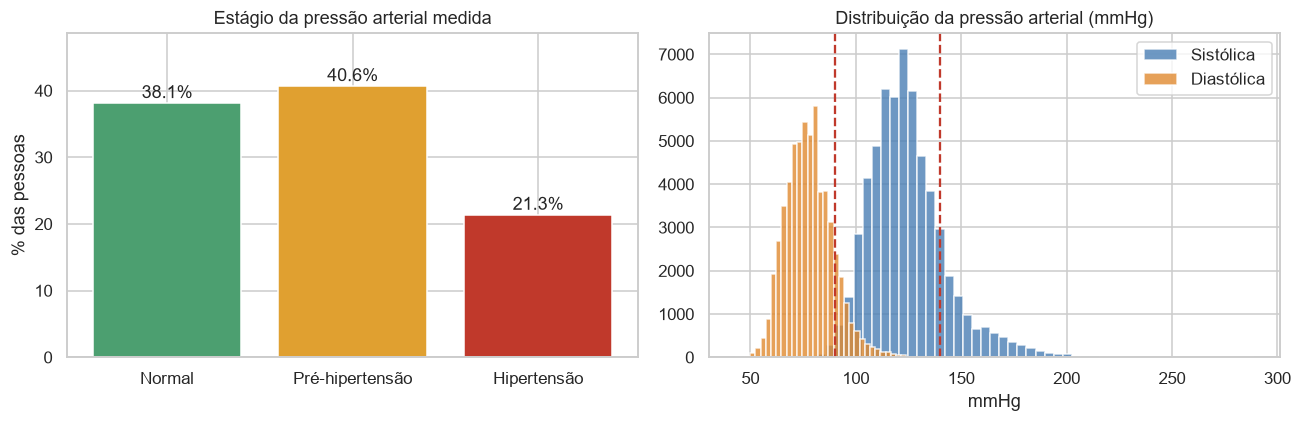

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ordem = ["Normal", "Pré-hipertensão", "Hipertensão"]
cont = limpa["estagio"].value_counts(normalize=True).reindex(ordem) * 100
ax[0].bar(ordem, cont.values, color=["#4c9f70", "#e0a030", "#c0392b"])
for i, v in enumerate(cont.values): ax[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax[0].set_title("Estágio da pressão arterial medida"); ax[0].set_ylabel("% das pessoas"); ax[0].set_ylim(0, cont.max() + 8)

ax[1].hist(limpa["pa_sistolica"], bins=50, color="#4a7fb5", alpha=.8, label="Sistólica")
ax[1].hist(limpa["pa_diastolica"], bins=50, color="#e08a30", alpha=.8, label="Diastólica")
ax[1].axvline(140, color="#c0392b", ls="--"); ax[1].axvline(90, color="#c0392b", ls="--")
ax[1].set_title("Distribuição da pressão arterial (mmHg)"); ax[1].set_xlabel("mmHg"); ax[1].legend()
plt.tight_layout(); salvar("01_estagios_e_distribuicao_pa"); plt.show()

In [8]:
# Medida x diagnóstico: as duas definições de hipertensão discordam bastante
tab = pd.crosstab(limpa["diagnostico"].map({0: "Sem diagnóstico médico", 1: "Com diagnóstico médico"}),
                  limpa["pa_medida_alta"].map({0: "PA medida < 140/90", 1: "PA medida ≥ 140/90"}), margins=True)
tab

pa_medida_alta,PA medida < 140/90,PA medida ≥ 140/90,All
diagnostico,,,
Com diagnóstico médico,6978,5475,12453
Sem diagnóstico médico,39762,7187,46949
All,46740,12662,59402


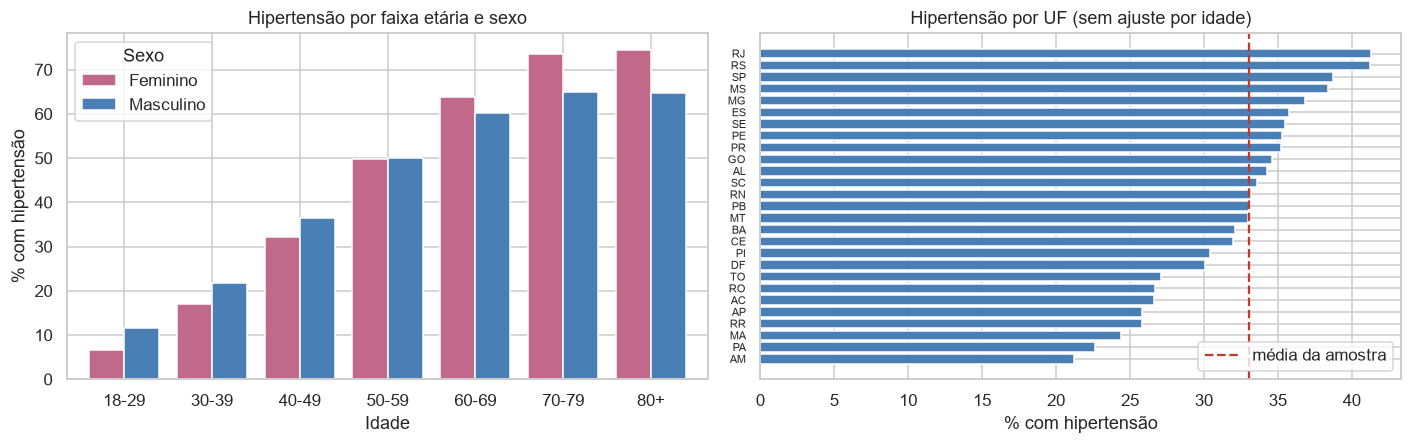

In [9]:
faixas = pd.cut(limpa["idade"], [17, 29, 39, 49, 59, 69, 79, 120],
                labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"])
prev_idade = limpa.groupby([faixas, limpa["sexo_masc"].map({0: "Feminino", 1: "Masculino"})],
                           observed=True)["hipertensao"].mean().unstack() * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
prev_idade.plot(kind="bar", ax=ax[0], color=["#c0698b", "#4a7fb5"], width=.8)
ax[0].set_title("Hipertensão por faixa etária e sexo"); ax[0].set_ylabel("% com hipertensão"); ax[0].set_xlabel("Idade")
ax[0].tick_params(axis="x", rotation=0); ax[0].legend(title="Sexo")

prev_uf = limpa.groupby("uf")["hipertensao"].mean().sort_values() * 100
ax[1].barh(prev_uf.index, prev_uf.values, color="#4a7fb5")
ax[1].axvline(limpa["hipertensao"].mean() * 100, color="#c0392b", ls="--", label="média da amostra")
ax[1].set_title("Hipertensão por UF (sem ajuste por idade)"); ax[1].set_xlabel("% com hipertensão"); ax[1].legend()
ax[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); salvar("02_hipertensao_por_idade_sexo_uf"); plt.show()

**Observações:** a hipertensão cresce de forma muito clara com a idade, e as diferenças entre UFs são pequenas perto disso. Parte da diferença entre UFs vem apenas da idade média de cada estado.

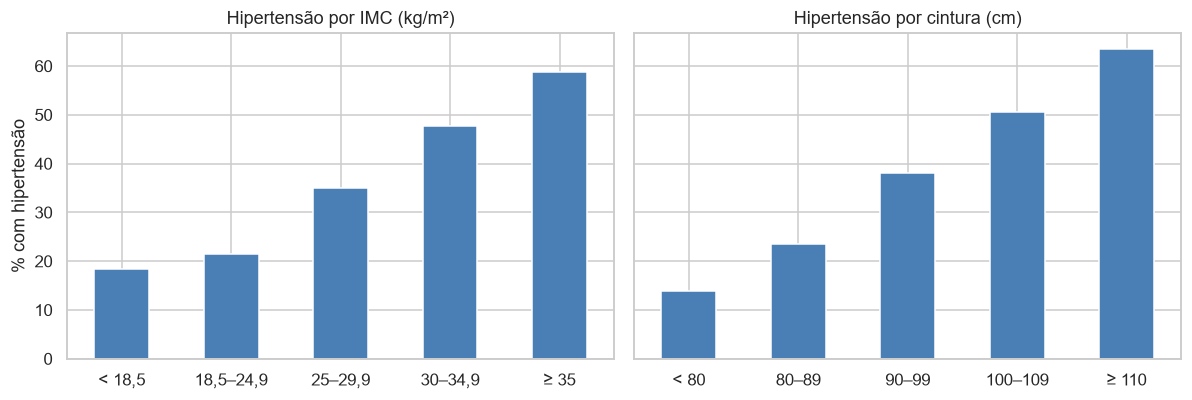

In [10]:
cat_imc = pd.cut(modelagem["imc"], [0, 18.5, 25, 30, 35, 100], labels=["< 18,5", "18,5–24,9", "25–29,9", "30–34,9", "≥ 35"], right=False)
cat_cint = pd.cut(modelagem["cintura"], [0, 80, 90, 100, 110, 300], labels=["< 80", "80–89", "90–99", "100–109", "≥ 110"], right=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
(modelagem.groupby(cat_imc, observed=True)["hipertensao"].mean() * 100).plot(kind="bar", ax=ax[0], color="#4a7fb5")
ax[0].set_title("Hipertensão por IMC (kg/m²)"); ax[0].set_ylabel("% com hipertensão"); ax[0].set_xlabel("")
(modelagem.groupby(cat_cint, observed=True)["hipertensao"].mean() * 100).plot(kind="bar", ax=ax[1], color="#4a7fb5")
ax[1].set_title("Hipertensão por cintura (cm)"); ax[1].set_xlabel("")
for a in ax: a.tick_params(axis="x", rotation=0)
plt.tight_layout(); salvar("03_hipertensao_por_imc_e_cintura"); plt.show()

## 6. Treino e avaliação

* **Divisão treino/teste por conglomerado (`UPA_PNS`)**: pessoas do mesmo setor/domicílio são parecidas; se estivessem uma no treino e outra no teste, a métrica ficaria inflada. 80% dos conglomerados vão para treino e 20% para teste.
* **Modelos comparados** (todos de classificação supervisionada):
  * *Só idade* (referência simples);
  * *Mínimo*: UF + idade + sexo, **regressão logística** (o que o relatório prevê como entrada);
  * *Estendido*: mínimo + IMC + cintura + diabetes + fumo, **regressão logística**;
  * *Estendido – Gradient Boosting*: mesmo conjunto, algoritmo mais complexo, só para comparar.
* **Métricas:** AUC (separação entre quem tem e quem não tem hipertensão; 0,5 = sorteio, 1 = perfeito), precisão média (AP) e Brier (qualidade das probabilidades; menor é melhor).

In [11]:
sep = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE)
idx_tr, idx_te = next(sep.split(modelagem, groups=modelagem["UPA_PNS"]))
treino, teste = modelagem.iloc[idx_tr], modelagem.iloc[idx_te]
print(f"Treino: {len(treino):,} pessoas | Teste: {len(teste):,} pessoas".replace(",", "."))
print(f"Prevalência  treino: {treino['hipertensao'].mean():.1%}  | teste: {teste['hipertensao'].mean():.1%}")

NUM_MIN, CAT_MIN = ["idade", "sexo_masc"], ["uf"]
NUM_EXT = NUM_MIN + ["imc", "cintura", "diabetes", "fuma"]

def pipeline(num, cat, algoritmo="logistica"):
    if algoritmo == "logistica":
        pre = ColumnTransformer([("num", StandardScaler(), num),
                                 ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
        modelo = LogisticRegression(max_iter=2000)
    else:
        pre = ColumnTransformer([("num", "passthrough", num),
                                 ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
        modelo = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, random_state=SEMENTE)
    return Pipeline([("pre", pre), ("modelo", modelo)])

CONFIGS = {
    "Só idade":                       (["idade"], [], "logistica"),
    "Mínimo (UF+idade+sexo)":         (NUM_MIN, CAT_MIN, "logistica"),
    "Estendido (+IMC, cintura, diabetes, fumo)": (NUM_EXT, CAT_MIN, "logistica"),
    "Estendido – Gradient Boosting":  (NUM_EXT, CAT_MIN, "gb"),
}

resultados, probas = [], {}
for nome, (num, cat, alg) in CONFIGS.items():
    m = pipeline(num, cat, alg).fit(treino[num + cat], treino["hipertensao"])
    p = m.predict_proba(teste[num + cat])[:, 1]
    probas[nome] = p
    # validação cruzada (por conglomerado) só no treino, para ver a estabilidade
    cv = cross_val_score(pipeline(num, cat, alg), treino[num + cat], treino["hipertensao"],
                         groups=treino["UPA_PNS"], cv=GroupKFold(5), scoring="roc_auc")
    resultados.append({"Modelo": nome,
                       "AUC (teste)": roc_auc_score(teste["hipertensao"], p),
                       "AUC (CV 5 pastas)": f"{cv.mean():.3f} ± {cv.std():.3f}",
                       "Precisão média": average_precision_score(teste["hipertensao"], p),
                       "Brier": brier_score_loss(teste["hipertensao"], p)})

tabela = pd.DataFrame(resultados).set_index("Modelo")
tabela.to_csv(PASTA_DADOS / "metricas_modelos.csv", sep=";", decimal=",")
tabela.round(3)

Treino: 45.082 pessoas | Teste: 11.355 pessoas
Prevalência  treino: 32.6%  | teste: 32.5%


,AUC (teste),AUC (CV 5 pastas),Precisão média,Brier
Modelo,,,,
Só idade,0.768,0.770 ± 0.002,0.581,0.178
Mínimo (UF+idade+sexo),0.772,0.774 ± 0.003,0.588,0.177
"Estendido (+IMC, cintura, diabetes, fumo)",0.803,0.805 ± 0.004,0.650,0.164
Estendido – Gradient Boosting,0.804,0.805 ± 0.003,0.656,0.164


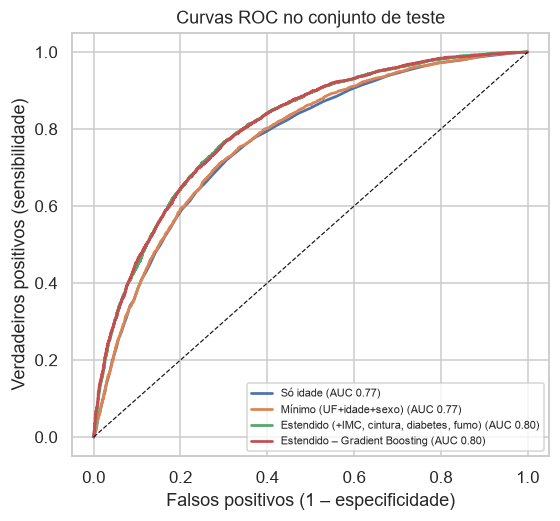

In [12]:
fig, ax = plt.subplots(figsize=(5.6, 5))
for nome, p in probas.items():
    fpr, tpr, _ = roc_curve(teste["hipertensao"], p)
    ax.plot(fpr, tpr, label=f"{nome} (AUC {roc_auc_score(teste['hipertensao'], p):.2f})", lw=1.8)
ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.set_xlabel("Falsos positivos (1 – especificidade)"); ax.set_ylabel("Verdadeiros positivos (sensibilidade)")
ax.set_title("Curvas ROC no conjunto de teste"); ax.legend(fontsize=7, loc="lower right")
salvar("04_curvas_roc"); plt.show()

**Leitura dos resultados**

* A **idade sozinha** já explica a maior parte do que o modelo consegue; UF e sexo acrescentam muito pouco.
* Acrescentar **IMC, cintura, diabetes e fumo** melhora a separação de forma visível.
* O **Gradient Boosting não melhora** a regressão logística. Por isso usamos a regressão logística: é mais simples, interpretável e pode ser reproduzida direto no navegador, sem servidor.

### 6.1 Importância das variáveis (modelo estendido)

Em regressão logística, `exp(coeficiente)` é o *odds ratio*: quanto multiplica a chance de hipertensão para cada aumento de **1 desvio-padrão** (variáveis numéricas padronizadas) ou para a presença do fator (variáveis 0/1 também padronizadas aqui). Mantemos a escala padronizada para comparar a força das variáveis.

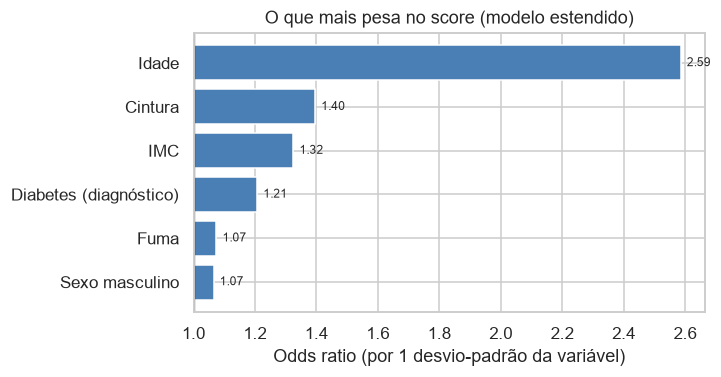

In [13]:
m_ext = pipeline(NUM_EXT, CAT_MIN).fit(treino[NUM_EXT + CAT_MIN], treino["hipertensao"])
coef = pd.Series(m_ext.named_steps["modelo"].coef_[0],
                 index=m_ext.named_steps["pre"].get_feature_names_out())
coef = coef[coef.index.str.startswith("num__")]
coef.index = coef.index.str.replace("num__", "")
nomes = {"idade": "Idade", "sexo_masc": "Sexo masculino", "imc": "IMC", "cintura": "Cintura",
         "diabetes": "Diabetes (diagnóstico)", "fuma": "Fuma"}
odds = np.exp(coef).rename(index=nomes).sort_values()

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.barh(odds.index, odds.values - 1, left=1, color="#4a7fb5")
ax.axvline(1, color="k", lw=.8)
for y, v in enumerate(odds.values): ax.text(v + .02, y, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("Odds ratio (por 1 desvio-padrão da variável)"); ax.set_title("O que mais pesa no score (modelo estendido)")
salvar("05_importancia_variaveis"); plt.show()

## 7. Score de 0 a 10 e faixas de risco

A regressão logística devolve a **probabilidade estimada** de hipertensão. O score é essa probabilidade em escala de 0 a 10:

`score = parte inteira de (probabilidade × 10 + 0,5)`  (arredondamento comum, igual no Python e no JavaScript)

As **faixas de risco são definidas pelo próprio score**, para nunca haver contradição na tela: 0–2 = Baixo, 3–4 = Moderado, 5–6 = Elevado, 7–10 = Muito elevado. A tabela mostra, no **conjunto de teste**, quantas pessoas caem em cada faixa e qual a proporção que de fato tem hipertensão, o que verifica se o score faz sentido (a proporção real deve subir de faixa em faixa).

In [14]:
FAIXAS = [(0, 2, "Baixo"), (3, 4, "Moderado"), (5, 6, "Elevado"), (7, 10, "Muito elevado")]

def calcular_score(p):
    return int(np.floor(p * 10 + 0.5))          # 0 a 10

def faixa(score):
    for lo, hi, nome in FAIXAS:
        if lo <= score <= hi: return nome

chave = "Estendido (+IMC, cintura, diabetes, fumo)"
aval = pd.DataFrame({"p": probas[chave], "real": teste["hipertensao"].values})
aval["score"] = aval["p"].map(calcular_score)
aval["faixa"] = aval["score"].map(faixa)

ordem_f = [f[2] for f in FAIXAS]
resumo = (aval.groupby("faixa").agg(pessoas=("real", "size"), hipertensos_reais=("real", "mean"), prob_media_prevista=("p", "mean"))
          .reindex(ordem_f))
resumo["% das pessoas"] = resumo["pessoas"] / resumo["pessoas"].sum() * 100
resumo[["hipertensos_reais", "prob_media_prevista"]] *= 100
resumo.round(1)

,pessoas,hipertensos_reais,prob_media_prevista,% das pessoas
faixa,,,,
Baixo,5599,12.3,12.7,49.3
Moderado,2577,37.1,34.2,22.7
Elevado,1739,55.5,54.4,15.3
Muito elevado,1440,75.1,77.1,12.7


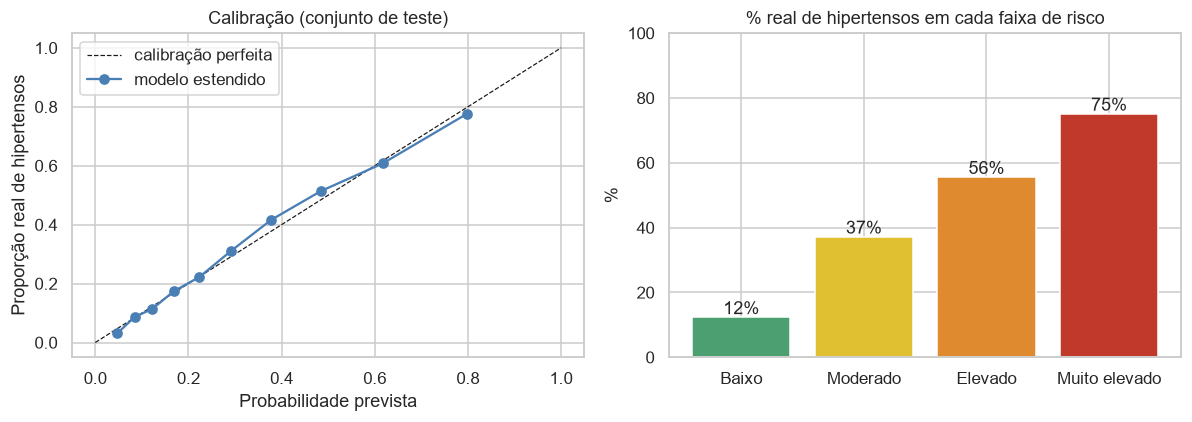

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fr, mp = calibration_curve(aval["real"], aval["p"], n_bins=10, strategy="quantile")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8, label="calibração perfeita")
ax[0].plot(mp, fr, "o-", color="#4a7fb5", label="modelo estendido")
ax[0].set_xlabel("Probabilidade prevista"); ax[0].set_ylabel("Proporção real de hipertensos")
ax[0].set_title("Calibração (conjunto de teste)"); ax[0].legend()

cores = ["#4c9f70", "#e0c030", "#e08a30", "#c0392b"]
ax[1].bar(ordem_f, resumo["hipertensos_reais"], color=cores)
for i, v in enumerate(resumo["hipertensos_reais"]): ax[1].text(i, v + 1, f"{v:.0f}%", ha="center")
ax[1].set_title("% real de hipertensos em cada faixa de risco"); ax[1].set_ylabel("%"); ax[1].set_ylim(0, 100)
plt.tight_layout(); salvar("06_calibracao_e_faixas"); plt.show()

## 8. Modelos finais e exportação para o site

Depois de avaliar com a divisão treino/teste, **reajustamos os dois modelos de regressão logística com todas as pessoas** do conjunto de modelagem e exportamos os coeficientes.

Para reproduzir no navegador sem biblioteca nenhuma, convertemos a regressão logística em uma fórmula simples:

`logit = intercepto + Σ peso_i × (valor_i − média_i) / desvio_i + peso_UF`   →   `probabilidade = 1 / (1 + e^(−logit))`

O arquivo `modelo-dados.js` (e o `modelo.json` equivalente) leva os números da fórmula; o `modelo-risco.js` faz a conta.

In [16]:
def exportar(num, cat):
    m = pipeline(num, cat).fit(modelagem[num + cat], modelagem["hipertensao"])
    pre, lr = m.named_steps["pre"], m.named_steps["modelo"]
    esc = pre.named_transformers_["num"]; ohe = pre.named_transformers_["cat"]
    w = lr.coef_[0]; n = len(num)
    return m, {
        "intercepto": float(lr.intercept_[0]),
        "numericas": {c: {"media": float(esc.mean_[i]), "desvio": float(esc.scale_[i]), "peso": float(w[i])}
                      for i, c in enumerate(num)},
        "uf": {u: float(w[n + j]) for j, u in enumerate(ohe.categories_[0])},
    }

m_min, json_min = exportar(NUM_MIN, CAT_MIN)
m_ext_final, json_ext = exportar(NUM_EXT, CAT_MIN)

modelo = {
    "descricao": "Regressão logística – risco de hipertensão arterial (PNS 2013). Probabilidade = 1/(1+exp(-logit)). Score = floor(prob*10+0.5).",
    "base": "IBGE – Pesquisa Nacional de Saúde 2013",
    "pessoas_treino": int(len(modelagem)),
    "faixas": [{"score_min": lo, "score_max": hi, "nome": nome} for lo, hi, nome in FAIXAS],
    "minimo": json_min,
    "estendido": json_ext,
    "auc_teste": {"minimo": round(float(roc_auc_score(teste['hipertensao'], probas['Mínimo (UF+idade+sexo)'])), 3),
                  "estendido": round(float(roc_auc_score(teste['hipertensao'], probas[chave])), 3)},
}
_ = (PASTA_SITE / "modelo.json").write_text(json.dumps(modelo, ensure_ascii=False, indent=2), encoding="utf-8")
_ = (PASTA_SITE / "modelo-dados.js").write_text(
    "// Gerado automaticamente por ml/01_limpeza_e_modelo.ipynb – não editar à mão.\n"
    "const MODELO_RISCO = " + json.dumps(modelo, ensure_ascii=False, indent=2) + ";\n", encoding="utf-8")
print("Exportado em", PASTA_SITE.resolve())

Exportado em C:\Users\xancl\Downloads\Quick Share\PROJETO INTEGRADOR 4\repositorio\src\data


### 8.1 Conferência: a fórmula exportada dá o mesmo resultado do scikit-learn?

Recalculamos as probabilidades à mão (como o navegador fará) e comparamos com `predict_proba`. Também gravamos alguns casos de teste em `dados/casos_teste.json`, usados para conferir o JavaScript da página.

In [17]:
def prob_manual(spec, linha, num):
    z = spec["intercepto"] + spec["uf"][linha["uf"]]
    for c in num:
        s = spec["numericas"][c]
        z += s["peso"] * (linha[c] - s["media"]) / s["desvio"]
    return 1 / (1 + np.exp(-z))

amostra = modelagem.sample(2000, random_state=SEMENTE)
for nome, m, spec, num in [("mínimo", m_min, json_min, NUM_MIN), ("estendido", m_ext_final, json_ext, NUM_EXT)]:
    p_sk = m.predict_proba(amostra[num + CAT_MIN])[:, 1]
    p_me = np.array([prob_manual(spec, r, num) for r in amostra.to_dict("records")])
    print(f"Modelo {nome}: diferença máxima = {np.abs(p_sk - p_me).max():.2e}")
    assert np.abs(p_sk - p_me).max() < 1e-9

casos = []
for r in amostra.head(12).to_dict("records"):
    entrada = {c: (float(r[c]) if c != "uf" else r[c]) for c in NUM_EXT + ["uf"]}
    casos.append({"entrada": entrada,
                  "prob_minimo": float(prob_manual(json_min, r, NUM_MIN)),
                  "prob_estendido": float(prob_manual(json_ext, r, NUM_EXT)),
                  "score_minimo": calcular_score(prob_manual(json_min, r, NUM_MIN)),
                  "score_estendido": calcular_score(prob_manual(json_ext, r, NUM_EXT))})
_ = (PASTA_DADOS / "casos_teste.json").write_text(json.dumps(casos, indent=1), encoding="utf-8")

Modelo mínimo: diferença máxima = 2.22e-16
Modelo estendido: diferença máxima = 2.22e-16


## 9. Exemplos de uso

In [18]:
def risco(uf, idade, sexo_masc, imc=None, cintura=None, diabetes=None, fuma=None):
    estendido = None not in (imc, cintura, diabetes, fuma)
    num = NUM_EXT if estendido else NUM_MIN
    spec = json_ext if estendido else json_min
    linha = dict(uf=uf, idade=idade, sexo_masc=sexo_masc, imc=imc, cintura=cintura, diabetes=diabetes, fuma=fuma)
    p = prob_manual(spec, linha, num)
    sc = calcular_score(p)
    return f"{'estendido' if estendido else 'mínimo   '} | prob. {p:.0%} | score {sc}/10 | faixa {faixa(sc)}"

print("Mulher, 35 anos, SP     :", risco("SP", 35, 0))
print("Homem, 55 anos, BA      :", risco("BA", 55, 1))
print("Homem, 55 anos, BA +med.:", risco("BA", 55, 1, imc=31, cintura=104, diabetes=1, fuma=0))
print("Mulher, 72 anos, RS     :", risco("RS", 72, 0))

Mulher, 35 anos, SP     : mínimo    | prob. 22% | score 2/10 | faixa Baixo
Homem, 55 anos, BA      : mínimo    | prob. 48% | score 5/10 | faixa Elevado
Homem, 55 anos, BA +med.: estendido | prob. 77% | score 8/10 | faixa Muito elevado
Mulher, 72 anos, RS     : mínimo    | prob. 74% | score 7/10 | faixa Muito elevado


## 10. Limitações (para o relatório)

* **Dados de 2013.** O perfil da população e os hábitos mudaram. A PNS 2019 (mais recente com microdados) tem pressão medida só numa subamostra pequena, e a PNS 2026 ainda está em coleta. Vale validar o modelo em dados mais novos quando possível.
* **Amostra complexa.** A PNS usa amostragem por conglomerados com pesos. Aqui o modelo foi treinado **sem pesos amostrais**, e a prevalência da amostra (~33%) **não é a prevalência da população brasileira**. O objetivo é ordenar o risco individual, não estimar prevalências nacionais (para isso seria preciso usar `V00291`).
* **Medição em uma única ocasião.** O diagnóstico clínico de hipertensão exige medições repetidas; a pressão final da PNS é a média de medições em uma única visita.
* **Diagnóstico autorreferido** depende de a pessoa já ter acessado o sistema de saúde.
* **Município não existe na PNS 2013.** A localização mais fina é a UF; o efeito da UF no score é pequeno.
* **Uso:** apoio à triagem, nunca substitui a medição da pressão nem a avaliação profissional.